# Chapter 21: Random Is Not the Same as Equal

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** rebuild four small probability models one outcome at a time: one die and the walls at 0 and 1, the 36 ordered pairs of two dice, a bag of tokens that changes when you take one out, and the eight paths of three coin flips. In each, you list the outcomes first, check that they are equally likely, and only then count.

The code cells are optional reading. Every result and picture is shown right below the code, so you can follow along without running anything.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from fractions import Fraction as F

INK, TERRACOTTA, NAVY, TEAL, GREY, LIGHT = "#222222", "#c0563b", "#1f3a5f", "#2a8a85", "#777777", "#dddddd"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def ft(x):
    """Write a Fraction the way the book does: 1/3, 2/3, 1."""
    x = F(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def bare(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
print("Setup done.")

Setup done.


## Demonstration 1: Zero and one are the walls

**The question, in plain words:** On one fair die, how small and how large can the probability of an event get?

**The equations:**

$$0 \le P(E) \le 1 \qquad\qquad 2/6 = 1/3$$

**What the symbols mean:**
- $E$ is an *event*: a stated collection of outcomes, such as "roll more than 4".
- $P(E)$ means "the probability of event $E$".
- The six faces 1 through 6 are the equally likely outcomes.
- The *complement* of an event is every face that is **not** in it.

**Predict first:** change the event to "roll more than 6". How many faces belong, and what is the probability?

In [2]:
faces = [1, 2, 3, 4, 5, 6]
threshold = 4                      # event: roll more than 4
fav = [f for f in faces if f > threshold]
rest = [f for f in faces if f <= threshold]
p, q = F(len(fav), 6), F(len(rest), 6)

print(f"Event: roll more than {threshold}")
print(f"Favorable faces: {fav}  ({len(fav)} of 6)")
print(f"P(more than {threshold}) = {len(fav)}/6 = {ft(p)}")
print(f"Complement (at most {threshold}): faces {rest}  ({len(rest)} of 6)")
print(f"P(at most {threshold}) = {len(rest)}/6 = {ft(q)}")
print(f"Check: {ft(p)} + {ft(q)} = {ft(p + q)}")
print()
print("Other menu values:")
print("threshold | favorable | P(event)    | P(complement) | sum")
for t in [0, 2, 4, 6]:
    f_ = sum(1 for f in faces if f > t)
    pe, pc = F(f_, 6), F(6 - f_, 6)
    print(f"   {t}      |    {f_}      | {f_}/6 = {ft(pe):<5} | {6 - f_}/6 = {ft(pc):<5}   | {ft(pe + pc)}")

Event: roll more than 4
Favorable faces: [5, 6]  (2 of 6)
P(more than 4) = 2/6 = 1/3
Complement (at most 4): faces [1, 2, 3, 4]  (4 of 6)
P(at most 4) = 4/6 = 2/3
Check: 1/3 + 2/3 = 1

Other menu values:
threshold | favorable | P(event)    | P(complement) | sum
   0      |    6      | 6/6 = 1     | 0/6 = 0       | 1
   2      |    4      | 4/6 = 2/3   | 2/6 = 1/3     | 1
   4      |    2      | 2/6 = 1/3   | 4/6 = 2/3     | 1
   6      |    0      | 0/6 = 0     | 6/6 = 1       | 1


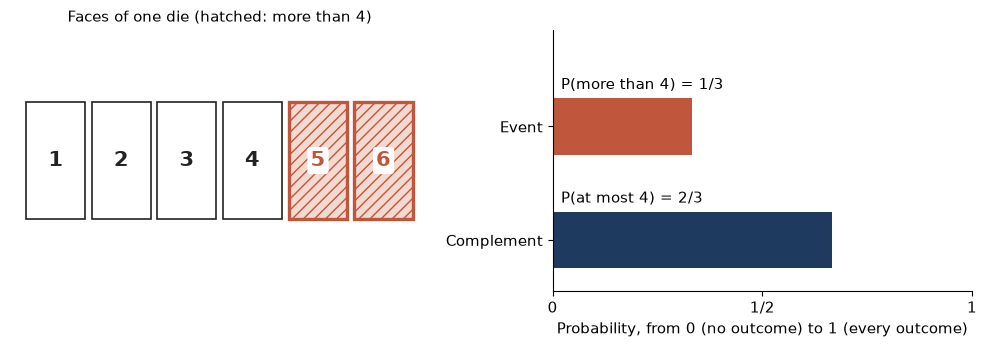

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
for f in faces:
    hit = f in fav
    left.add_patch(Rectangle((f - 0.45, 0.55), 0.9, 0.9, facecolor="#f3d9cf" if hit else "white",
                             edgecolor=TERRACOTTA if hit else INK, linewidth=2.4 if hit else 1.2,
                             hatch="///" if hit else None))
    left.text(f, 1.0, str(f), ha="center", va="center", fontsize=15, fontweight="bold",
              color=TERRACOTTA if hit else INK, bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
left.set_xlim(0.3, 6.7); left.set_ylim(0, 2); bare(left)
left.set_title(f"Faces of one die (hatched: more than {threshold})", fontsize=11)

right.barh([1], [float(p)], color=TERRACOTTA, height=0.5)
right.barh([0], [float(q)], color=NAVY, height=0.5)
right.text(0.02, 1.33, f"P(more than {threshold}) = {ft(p)}", fontsize=10.5)
right.text(0.02, 0.33, f"P(at most {threshold}) = {ft(q)}", fontsize=10.5)
right.set_xlim(0, 1); right.set_ylim(-0.45, 1.85)
right.set_xticks([0, 0.5, 1]); right.set_xticklabels(["0", "1/2", "1"])
right.set_yticks([0, 1]); right.set_yticklabels(["Complement", "Event"])
right.set_xlabel("Probability, from 0 (no outcome) to 1 (every outcome)")
plt.tight_layout(); plt.show()

**What this shows:** a probability here is *favorable faces over 6*. The count can never go below 0 or above 6, so the probability stays between 0 and 1. An event and its complement split the six faces between them, so their probabilities always add to 1.

**Where it stops working:** the counting shortcut needs equally likely outcomes. A spinner with three quarters of its area blue would not give its two colors equal probability, so you could not just count "1 of 2". If a probability you compute comes out negative or above 1, stop and recount: something was left out, counted twice, or divided by the wrong total.

## Demonstration 2: Eleven sums, thirty-six pairs

**The question, in plain words:** Two fair dice can show sums from 2 to 12. Why is 7 more likely than 2?

**The equations:**

$$6 \times 6 = 36 \qquad\qquad 6/36 = 1/6$$

**What the symbols mean:**
- An *ordered pair* (die 1, die 2) records which die showed which value, so $(2,5)$ and $(5,2)$ are different outcomes.
- The 36 ordered pairs are the equally likely outcomes.
- A *sum* is an event: the collection of pairs that add up to it.

**Predict first:** before looking at the sum 12, guess how many cells of the grid will be outlined.

In [4]:
target = 7
pairs = [(i, j) for i in range(1, 7) for j in range(1, 7) if i + j == target]
print("Ordered pairs in the grid: 6 x 6 =", 6 * 6)
print(f"Pairs with sum {target}: {len(pairs)}")
print("  " + ", ".join(f"({i}, {j})" for i, j in pairs))
print(f"Each pair has chance (1/6)(1/6) = 1/36")
print(f"P(sum {target}) = {len(pairs)} x 1/36 = {len(pairs)}/36 = {ft(F(len(pairs), 36))}")
print()
print("Other menu values:")
for t in [2, 7, 10, 12]:
    n = sum(1 for i in range(1, 7) for j in range(1, 7) if i + j == t)
    print(f"sum {t:>2}: {n} pair(s), P = {n}/36 = {ft(F(n, 36))}")

Ordered pairs in the grid: 6 x 6 = 36
Pairs with sum 7: 6
  (1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)
Each pair has chance (1/6)(1/6) = 1/36
P(sum 7) = 6 x 1/36 = 6/36 = 1/6

Other menu values:
sum  2: 1 pair(s), P = 1/36 = 1/36
sum  7: 6 pair(s), P = 6/36 = 1/6
sum 10: 3 pair(s), P = 3/36 = 1/12
sum 12: 1 pair(s), P = 1/36 = 1/36


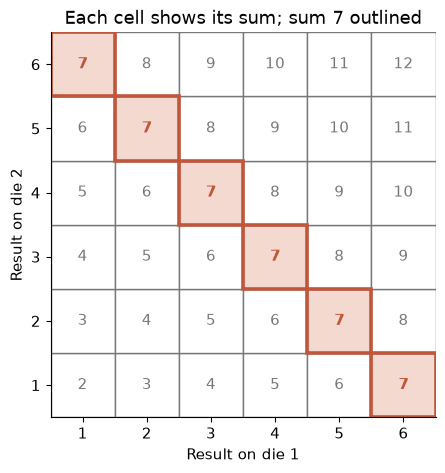

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 5))
for i in range(1, 7):
    for j in range(1, 7):
        hit = i + j == target
        ax.add_patch(Rectangle((i - 0.5, j - 0.5), 1, 1, facecolor="#f3d9cf" if hit else "white", edgecolor=GREY))
        ax.text(i, j, str(i + j), ha="center", va="center", color=TERRACOTTA if hit else GREY,
                fontweight="bold" if hit else "normal")
for i, j in pairs:
    ax.add_patch(Rectangle((i - 0.5, j - 0.5), 1, 1, fill=False, edgecolor=TERRACOTTA, linewidth=2.6))
ax.set_xlim(0.5, 6.5); ax.set_ylim(0.5, 6.5); ax.set_aspect("equal")
ax.set_xticks(range(1, 7)); ax.set_yticks(range(1, 7))
ax.set_xlabel("Result on die 1"); ax.set_ylabel("Result on die 2")
ax.set_title(f"Each cell shows its sum; sum {target} outlined")
plt.show()

**What this shows:** every cell is one ordered pair with chance $1/36$. Choosing a sum outlines the cells that add to it. Middle sums have more cells, so they collect more probability. There are 11 sum *labels*, but they are not 11 equal shares.

**Where it stops working:** the 36 pairs are equally likely only for two fair, independent dice. If the dice were somehow linked, the pairs would not all have chance $1/36$, and this count would fail. The habit to keep: before dividing by "the number of possible results", ask whether those results are equally likely. If not, go down to outcomes that are, and count those.

## Demonstration 3: Take a token out of the bag

**The question, in plain words:** Does the first draw change the chance of red on the second draw?

**The equations:**

$$P(\text{red before any draw}) = 2/3 \qquad\qquad P(\text{red after a red is kept out}) = 1/2$$

**What the symbols mean:**
- The bag holds two red tokens (R) and one blue token (B).
- $P(\text{red})$ is the chance the next draw is red.
- *Without replacement*: the first token stays out. *With replacement*: it goes back and the bag is mixed again.

**Predict first:** keep the token out and switch the first draw to blue. What is the chance of red on the second draw?

In [6]:
bag = ["red", "red", "blue"]

def second_draw(first, replace):
    after = list(bag)
    if not replace:
        after.remove(first)
    reds = after.count("red")
    return after, reds, F(reds, len(after))

print(f"Before draw 1: {bag}, P(red) = {bag.count('red')}/{len(bag)} = {ft(F(2, 3))}")
first, replace = "red", False      # the default: red drawn, kept out
after, reds, p2 = second_draw(first, replace)
print(f"Draw 1 is {first} and is kept out.")
print(f"Bag for draw 2: {after}  ({reds} red, {len(after) - reds} blue)")
print(f"P(red on draw 2) = {reds}/{len(after)} = {ft(p2)}")
print()
print("All four menu combinations:")
for rep in (False, True):
    for fc in ("red", "blue"):
        a, r, pp = second_draw(fc, rep)
        print(f"{'put back' if rep else 'kept out':<9} first={fc:<5} -> bag {a}, P(red) = {r}/{len(a)} = {ft(pp)}")

Before draw 1: ['red', 'red', 'blue'], P(red) = 2/3 = 2/3
Draw 1 is red and is kept out.
Bag for draw 2: ['red', 'blue']  (1 red, 1 blue)
P(red on draw 2) = 1/2 = 1/2

All four menu combinations:
kept out  first=red   -> bag ['red', 'blue'], P(red) = 1/2 = 1/2
kept out  first=blue  -> bag ['red', 'red'], P(red) = 2/2 = 1
put back  first=red   -> bag ['red', 'red', 'blue'], P(red) = 2/3 = 2/3
put back  first=blue  -> bag ['red', 'red', 'blue'], P(red) = 2/3 = 2/3


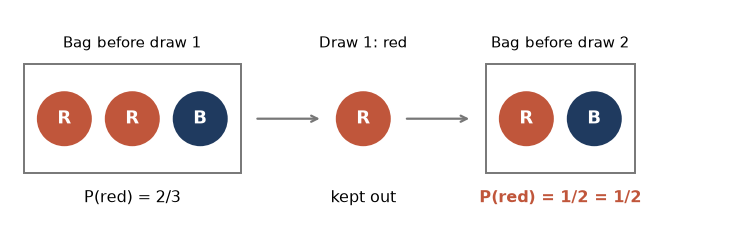

In [7]:
def token(ax, x, y, color):
    ax.add_patch(Circle((x, y), 0.42, facecolor=TERRACOTTA if color == "red" else NAVY, edgecolor="white", linewidth=1.5))
    ax.text(x, y, "R" if color == "red" else "B", ha="center", va="center", fontsize=13, fontweight="bold", color="white")

fig, ax = plt.subplots(figsize=(10, 3))
ax.add_patch(Rectangle((0, 1.2), 3.2, 1.6, fill=False, edgecolor=GREY, linewidth=1.4))
for k, c in enumerate(bag):
    token(ax, 0.6 + k, 2.0, c)
ax.text(1.6, 3.05, "Bag before draw 1", ha="center", fontsize=11)
ax.text(1.6, 0.95, "P(red) = 2/3", ha="center", va="top", fontsize=11.5)
token(ax, 5.0, 2.0, first)
ax.annotate("", xy=(4.4, 2.0), xytext=(3.4, 2.0), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.6))
ax.text(5.0, 3.05, f"Draw 1: {first}", ha="center", fontsize=11)
ax.text(5.0, 0.95, "kept out", ha="center", va="top", fontsize=11.5)
ax.annotate("", xy=(6.6, 2.0), xytext=(5.6, 2.0), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.6))
w = len(after) + 0.2
ax.add_patch(Rectangle((6.8, 1.2), w, 1.6, fill=False, edgecolor=GREY, linewidth=1.4))
for k, c in enumerate(sorted(after, key=lambda c: c != "red")):
    token(ax, 7.4 + k, 2.0, c)
ax.text(6.8 + w / 2, 3.05, "Bag before draw 2", ha="center", fontsize=11)
ax.text(6.8 + w / 2, 0.95, f"P(red) = {reds}/{len(after)} = {ft(p2)}", ha="center", va="top",
        fontsize=11.5, color=TERRACOTTA, fontweight="bold")
ax.set_xlim(-0.2, 10.3); ax.set_ylim(0.2, 3.6); ax.set_aspect("equal"); bare(ax)
plt.show()

**What this shows:** the second draw uses whatever is left in the bag. Taking a token out changes the bag, so the second chance depends on the first color: after a red it is $1/2$, after a blue it is $1$. Putting the token back restores the original bag, so the chance stays $2/3$ either way.

**Where it stops working:** the model assumes every token left in the bag is equally likely to be drawn. If the tokens are not mixed after one is returned, the $2/3$ no longer holds. For any repeated draw, write down what remains after the first result before you compute the second chance.

## Demonstration 4: Eight paths of three flips

**The question, in plain words:** In three fair flips, how likely is exactly two heads?

**The equations:**

$$2 \times 2 \times 2 = 8 \qquad\qquad (1/2)(1/2)(1/2) = 1/8$$

**What the symbols mean:**
- H is heads and T is tails. A path such as HTH lists the three flips in order.
- Each branch has probability $1/2$, so each complete path has $(1/2)(1/2)(1/2) = 1/8$.

**Predict first:** switch to "exactly one head". Will it have more paths, fewer, or the same number as exactly two heads?

In [8]:
from itertools import product
paths = ["".join(p) for p in product("HT", repeat=3)]
heads = 2
chosen = [p for p in paths if p.count("H") == heads]
print("All paths:", paths, f"(2 x 2 x 2 = {len(paths)})")
print("Each path: (1/2)(1/2)(1/2) =", ft(F(1, 2) ** 3))
print(f"Paths with exactly {heads} heads: {chosen}")
print(f"P(exactly {heads} heads) = {len(chosen)} x 1/8 = {len(chosen)}/8")
print()
print("Other menu values:")
for h in range(4):
    c = [p for p in paths if p.count("H") == h]
    print(f"{h} heads: {len(c)}/8 {c}")
print("Check the whole tree: " + " + ".join(str(sum(1 for p in paths if p.count('H') == h)) for h in range(4)) + " = 8")

All paths: ['HHH', 'HHT', 'HTH', 'HTT', 'THH', 'THT', 'TTH', 'TTT'] (2 x 2 x 2 = 8)
Each path: (1/2)(1/2)(1/2) = 1/8
Paths with exactly 2 heads: ['HHT', 'HTH', 'THH']
P(exactly 2 heads) = 3 x 1/8 = 3/8

Other menu values:
0 heads: 1/8 ['TTT']
1 heads: 3/8 ['HTT', 'THT', 'TTH']
2 heads: 3/8 ['HHT', 'HTH', 'THH']
3 heads: 1/8 ['HHH']
Check the whole tree: 1 + 3 + 3 + 1 = 8


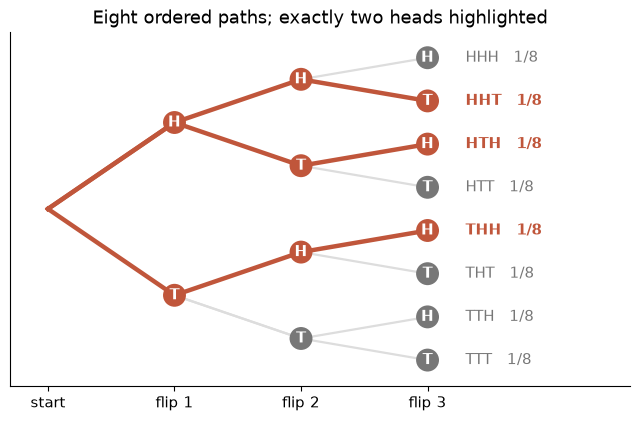

In [9]:
def y_of(prefix):
    k = len(prefix)
    if k == 0:
        return 3.5
    idx = int("".join("0" if c == "H" else "1" for c in prefix), 2)
    span = 8 // (2 ** k)
    return 7 - (idx * span + (span - 1) / 2)

fig, ax = plt.subplots(figsize=(8, 4.6))
for path in paths:
    hit = path in chosen
    for k in range(3):
        ax.plot([k, k + 1], [y_of(path[:k]), y_of(path[:k + 1])], color=TERRACOTTA if hit else LIGHT,
                linewidth=3.2 if hit else 1.6, zorder=2 if hit else 1)
seen = set()
for path in paths:
    for k in range(1, 4):
        pre = path[:k]
        if pre in seen:
            continue
        seen.add(pre)
        on = any(c.startswith(pre) for c in chosen)
        ax.text(k, y_of(pre), pre[-1], ha="center", va="center", color="white", fontweight="bold", zorder=3,
                bbox=dict(boxstyle="circle,pad=0.25", facecolor=TERRACOTTA if on else GREY, edgecolor="none"))
for path in paths:
    hit = path in chosen
    ax.text(3.3, y_of(path), f"{path}   1/8", va="center", color=TERRACOTTA if hit else GREY,
            fontweight="bold" if hit else "normal")
ax.set_xlim(-0.3, 4.6); ax.set_ylim(-0.6, 7.6); ax.set_yticks([])
ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["start", "flip 1", "flip 2", "flip 3"])
ax.set_title("Eight ordered paths; exactly two heads highlighted")
plt.show()

In [10]:
# Optional sanity check: a fixed-seed simulation lands near the exact counts.
rng = np.random.default_rng(21)
flips = rng.integers(0, 2, size=(100_000, 3))
share = np.mean(flips.sum(axis=1) == 2)
print(f"Simulated share with exactly two heads: {share:.3f}   (exact: 3/8 = {3/8:.3f})")

Simulated share with exactly two heads: 0.375   (exact: 3/8 = 0.375)


**What this shows:** the tree lists all eight ordered paths. HHT and THH have the same head count but are different paths, and each one counts. So three of the eight paths have exactly two heads, and the probability is $3/8$. The head counts 0, 1, 2, 3 collect $1 + 3 + 3 + 1 = 8$ paths.

**Where it stops working:** every path has chance $1/8$ only if the flips are fair and independent. A bent coin, or flips that influence each other, would make the paths unequal. A good habit: check an event two ways, once by listing outcomes and once by following a tree or grid. If the counts disagree, something was skipped or counted twice.

## Practice

**1.** On one fair die, what is the probability of rolling at most 2, and what is the probability of its complement?

<details><summary>Show answer</summary>

Faces 1 and 2 are in the event: $2/6 = 1/3$.
The complement is faces 3, 4, 5, 6: $4/6 = 2/3$.
Check: $1/3 + 2/3 = 1$.

</details>

**2.** How many ordered pairs of two dice give a sum of at least 10, and what is the probability?

<details><summary>Show answer</summary>

Sum 10 has 3 pairs, sum 11 has 2, sum 12 has 1.
Total: $3 + 2 + 1 = 6$ pairs.
Probability: $6/36 = 1/6$.

</details>

**3.** A bag holds three green and two yellow tokens. A green token is drawn and kept out. What is the chance the next token is green?

<details><summary>Show answer</summary>

Start: 3 green, 2 yellow (5 tokens).
After a green is kept out: 2 green, 2 yellow (4 tokens).
Chance of green: $2/4 = 1/2$. Reusing $3/5$ would ignore the removed token.

</details>